# Dispute-category classifier: training and evaluation (Phase 6.5)

Trains a Logistic Regression on **bge-m3 embeddings** (the same
embedding layer used by indexing and retrieval) to predict which of
the four dispute categories a user's first message belongs to.

**Run from the repo root or from `notebooks/`.** The first run
downloads/loads bge-m3, which can take a few minutes.

Outputs: accuracy, per-category precision/recall/F1, confusion
matrix, confidence histogram, and the saved model at
`src/dialogue/models/category_classifier_candidate.pkl`.

In [1]:
import sys
import os
import json
import hashlib
import importlib.metadata
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix)
from sklearn.model_selection import (
    StratifiedKFold, cross_val_score, train_test_split)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src/dialogue/category_classifier.py").is_file(), "Run from project root or notebooks/"
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.config import settings
from src.dialogue.category_classifier import CategoryClassifier
from src.dialogue.slot_schema import DisputeCategory

DATA_PATH = ROOT / "data" / "training_data" / "dispute_categories.csv"
RANDOM_STATE = 42
assert settings.EMBEDDING_MODEL_NAME == "BAAI/bge-m3"
MODEL_PATH = ROOT / "src/dialogue/models/category_classifier_candidate.pkl"
REPORT_PATH = MODEL_PATH.with_name("category_classifier_candidate_evaluation.json")
assert not MODEL_PATH.exists(), "Existing model: obtain approval before overwriting"
assert not REPORT_PATH.exists(), "Existing report: obtain approval before overwriting"
print("Python:", sys.executable, "Project:", ROOT)


Python: /home/kheyr/projects/az-legal-rag-latest/.venv-linux/bin/python Project: /home/kheyr/projects/az-legal-rag-latest


## 1. Load and check the dataset

In [2]:
df = pd.read_csv(DATA_PATH)
valid = {c.value for c in DisputeCategory}
assert set(df["category"]) == valid, "unknown category label"
assert not df["message"].duplicated().any(), "duplicate messages"
assert df["message"].notna().all() and df["message"].str.strip().ne("").all()
print(df["category"].value_counts())
df.sample(5, random_state=RANDOM_STATE)

category
UNLAWFUL_DISMISSAL        20
UNPAID_WAGES              20
UNPAID_OVERTIME           20
DENIED_OR_UNPAID_LEAVE    20
Name: count, dtype: int64


,message,category
30,"Maaşım vaxtında köçürülmür, ay sonunda yox, nö...",UNPAID_WAGES
0,Məni heç bir xəbərdarlıq etmədən işdən çıxardı...,UNLAWFUL_DISMISSAL
22,Şirkət mənə son üç ayın maaşını borcludur.,UNPAID_WAGES
31,Müəssisə işçilərin hesablaşmasını aparmadı və ...,UNPAID_WAGES
18,"Məni işdən çıxarma əmrini imzalatdılar, sonrad...",UNLAWFUL_DISMISSAL


## 2. Embed with bge-m3

Uses `CategoryClassifier.embed`, which wraps the project's
`EmbeddingManager` (normalised embeddings, same model as retrieval).

In [3]:
clf = CategoryClassifier()
X = clf.embed(df["message"].tolist())
y = df["category"].to_numpy()
print("Embedding matrix:", X.shape)
assert X.shape == (len(df), 1024)
assert np.isfinite(X).all()
np.testing.assert_allclose(np.linalg.norm(X, axis=1), 1.0, atol=1e-5)


/home/kheyr/projects/az-legal-rag-latest/.venv-linux/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[2026-10-11 00:18:56] [INFO] [src.indexing.vector_store]: Loading embedding model: BAAI/bge-m3


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 10398.92it/s]

Batches:   0%|          | 0/3 [00:00<?, ?it/s]

Batches:  33%|███▎      | 1/3 [00:01<00:02,  1.25s/it]

Batches: 100%|██████████| 3/3 [00:01<00:00,  2.70it/s]

Batches: 100%|██████████| 3/3 [00:01<00:00,  2.18it/s]

Embedding matrix: (80, 1024)


## 3. Stratified 80/20 train/test split

With only ~80 examples the test set is small (about 16 messages), so
single-split metrics are noisy. Section 4 adds cross-validation as a
more stable estimate.

In [4]:
idx = np.arange(len(df))
train_idx, test_idx = train_test_split(
    idx, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
print("train:", len(train_idx), "test:", len(test_idx))

train: 64 test: 16


## 4. Choose regularisation strength C

Chosen by cross-validation on the **training split only**, so the
test set stays untouched.

In [5]:
skf = StratifiedKFold(n_splits=5, shuffle=True,
                      random_state=RANDOM_STATE)
cv_scores = {}
for C in [0.1, 1, 10, 100]:
    scores = cross_val_score(
        LogisticRegression(C=C, max_iter=1000), X_train, y_train, cv=skf)
    cv_scores[C] = scores
    print(f"C={C:>6}: {scores.mean():.3f} +/- {scores.std():.3f}")
BEST_C = max(cv_scores, key=lambda C: cv_scores[C].mean())
print("Selected C:", BEST_C)


C=   0.1: 0.800 +/- 0.115
C=     1: 0.985 +/- 0.031


C=    10: 0.969 +/- 0.038


C=   100: 0.969 +/- 0.038
Selected C: 1


## 5. Train

C is selected using training-only cross-validation. The confidence threshold is selected from nested training-only OOF predictions before test evaluation.


### Training-only threshold selection
Nested OOF prevents each row from influencing either its predictor or that predictor's C selection. Require 95% accepted accuracy and 50% coverage; then maximize coverage. The held-out test is not accessed.


In [6]:
# Nested OOF: each row is predicted by a model that never saw that row.
# Inner C selection excludes the entire outer validation fold.
TARGET_ACCURACY = 0.95
MIN_COVERAGE = 0.50
candidate_thresholds = np.round(np.arange(0.25, 0.801, 0.01), 2)
oof_classes = np.unique(y_train)
oof_proba = np.zeros((len(y_train), len(oof_classes)))
fold_evidence = []
for fold, (fit_idx, val_idx) in enumerate(skf.split(X_train, y_train)):
    inner = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
    inner_scores = {C: float(cross_val_score(
        LogisticRegression(C=C, max_iter=1000),
        X_train[fit_idx], y_train[fit_idx], cv=inner).mean())
        for C in [0.1, 1, 10, 100]}
    fold_C = max(inner_scores, key=inner_scores.get)
    fold_model = LogisticRegression(C=fold_C, max_iter=1000)
    fold_model.fit(X_train[fit_idx], y_train[fit_idx])
    np.testing.assert_array_equal(fold_model.classes_, oof_classes)
    oof_proba[val_idx] = fold_model.predict_proba(X_train[val_idx])
    fold_evidence.append({"fold": fold, "C": fold_C,
        "fit_dataset_indices": train_idx[fit_idx].tolist(),
        "validation_dataset_indices": train_idx[val_idx].tolist(),
        "inner_accuracy": inner_scores})
oof_pred = oof_classes[oof_proba.argmax(axis=1)]
oof_conf = oof_proba.max(axis=1)
threshold_table = []
for t in candidate_thresholds:
    keep = oof_conf >= t
    row = {"threshold": float(t), "accepted_count": int(keep.sum()),
           "coverage": float(keep.mean()), "abstention_rate": float((~keep).mean()),
           "accepted_accuracy": float((oof_pred[keep] == y_train[keep]).mean()) if keep.any() else None}
    threshold_table.append(row)
feasible = [r for r in threshold_table if r["coverage"] >= MIN_COVERAGE
            and r["accepted_accuracy"] is not None and r["accepted_accuracy"] >= TARGET_ACCURACY]
assert feasible, "No threshold satisfies the predeclared accuracy and coverage requirements"
# Highest coverage subject to accuracy; ties prefer accuracy, then higher threshold.
selected = max(feasible, key=lambda r: (r["coverage"], r["accepted_accuracy"], r["threshold"]))
clf.threshold = selected["threshold"]
selection_evidence = {
    "procedure": "5-fold outer OOF on 64 training rows; 4-fold inner training-only C selection; grid 0.25..0.80 by 0.01; maximize coverage subject to accepted accuracy >=0.95 and coverage >=0.50; ties prefer accuracy then higher threshold",
    "target_accepted_accuracy": TARGET_ACCURACY, "minimum_coverage": MIN_COVERAGE,
    "selected": selected, "threshold_table": threshold_table,
    "oof_overall_accuracy": float((oof_pred == y_train).mean()),
    "folds": fold_evidence,
    "oof_rows": [{"dataset_index": int(train_idx[k]), "true": str(y_train[k]),
                  "predicted": str(oof_pred[k]), "confidence": float(oof_conf[k])}
                  for k in range(len(y_train))],
}
print("Training OOF selection:", json.dumps(selected))
print("OOF overall accuracy:", selection_evidence["oof_overall_accuracy"])


Training OOF selection: {"threshold": 0.32, "accepted_count": 64, "coverage": 1.0, "abstention_rate": 0.0, "accepted_accuracy": 0.984375}
OOF overall accuracy: 0.984375


In [7]:
clf.model.set_params(C=BEST_C)
clf.fit(X_train, y_train)
print("classes:", [c.value for c in clf.classes])

classes: ['DENIED_OR_UNPAID_LEAVE', 'UNLAWFUL_DISMISSAL', 'UNPAID_OVERTIME', 'UNPAID_WAGES']


## 6. Test-set metrics

In [8]:
proba = clf.predict_proba(X_test)
pred = np.array([clf.classes[k].value for k in proba.argmax(axis=1)])
conf = proba.max(axis=1)

print(f"Test accuracy: {accuracy_score(y_test, pred):.3f}\n")
print(classification_report(y_test, pred, digits=3, zero_division=0))
accepted = conf >= clf.threshold
coverage = float(accepted.mean())
accepted_accuracy = float((pred[accepted] == y_test[accepted]).mean()) if accepted.any() else None
print("Selected threshold:", clf.threshold)
print("Coverage:", coverage, "Abstention rate:", 1.0 - coverage)
print("Accepted accuracy:", accepted_accuracy)


Test accuracy: 0.938

                        precision    recall  f1-score   support

DENIED_OR_UNPAID_LEAVE      1.000     1.000     1.000         4
    UNLAWFUL_DISMISSAL      1.000     0.750     0.857         4
       UNPAID_OVERTIME      0.800     1.000     0.889         4
          UNPAID_WAGES      1.000     1.000     1.000         4

              accuracy                          0.938        16
             macro avg      0.950     0.938     0.937        16
          weighted avg      0.950     0.938     0.937        16

Selected threshold: 0.32
Coverage: 0.875 Abstention rate: 0.125
Accepted accuracy: 1.0


### Confusion matrix

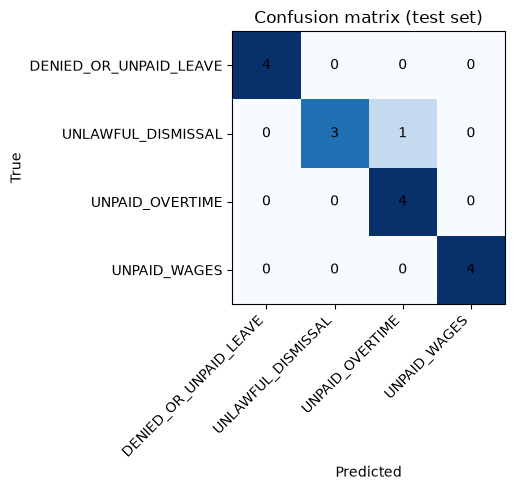

In [9]:
labels = [c.value for c in clf.classes]
cm = confusion_matrix(y_test, pred, labels=labels)

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, cm[i, j], ha="center", va="center")
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion matrix (test set)")
plt.tight_layout()
plt.show()

### Confidence distribution

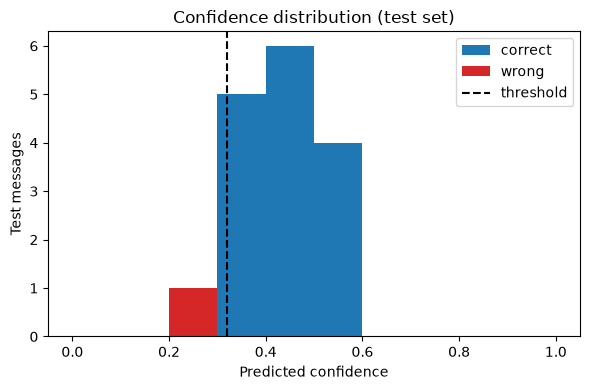

In [10]:
correct = pred == y_test
bins = np.linspace(0, 1, 11)
plt.figure(figsize=(6, 4))
plt.hist([conf[correct], conf[~correct]], bins=bins, stacked=True,
         label=["correct", "wrong"], color=["tab:blue", "tab:red"])
plt.axvline(clf.threshold, color="black",
            linestyle="--", label="threshold")
plt.xlabel("Predicted confidence")
plt.ylabel("Test messages")
plt.title("Confidence distribution (test set)")
plt.legend()
plt.tight_layout()
plt.show()

### Coverage vs accuracy at different thresholds

Only the threshold frozen from training OOF predictions is evaluated here.


In [11]:
print("Selected-threshold accepted count:", int(accepted.sum()), "of", len(y_test))


Selected-threshold accepted count: 14 of 16


### Training-only cross-validation

These scores were used for model selection; the held-out test is the independent evaluation.


In [12]:
cv = cv_scores[BEST_C]
print(f"Training-only 5-fold CV accuracy: {cv.mean():.3f} +/- {cv.std():.3f}")


Training-only 5-fold CV accuracy: 0.985 +/- 0.031


## 7. Save the model

In [13]:
assert not MODEL_PATH.exists(), "Existing model: refusing overwrite"
saved_path = clf.save(MODEL_PATH)
print("Saved to:", saved_path)


[2026-10-11 00:19:20] [INFO] [src.dialogue.category_classifier]: Saved classifier to /home/kheyr/projects/az-legal-rag-latest/src/dialogue/models/category_classifier_candidate.pkl


Saved to: /home/kheyr/projects/az-legal-rag-latest/src/dialogue/models/category_classifier_candidate.pkl


## 8. Reload and run inference

Held-out examples first, then messages that are **not** labour
disputes. Note: softmax probabilities are not calibrated for
out-of-scope text, so some off-topic messages may still pass the
threshold. Record what you observe.

In [14]:
loaded = CategoryClassifier.load(saved_path)
np.testing.assert_allclose(loaded.predict_proba(X_test), proba)
df_test = df.iloc[test_idx].reset_index(drop=True)

print("--- held-out examples ---")
for _, row in df_test.head(8).iterrows():
    p = loaded.predict(row["message"])
    shown = f"{p.category.value} ({p.confidence:.2f})" if p else "None"
    print(f"true={row['category']:<24} pred={shown}")
    print(f"   {row['message']}")

print("\n--- out-of-scope / vague messages ---")
for text in ["Salam, necəsiniz?", "Bakıda bu gün hava necədir?",
             "Mənim işdə problemim var."]:
    p = loaded.predict(text)
    shown = f"{p.category.value} ({p.confidence:.2f})" if p else "None"
    print(f"{text!r} -> {shown}")

--- held-out examples ---
[2026-10-11 00:19:20] [INFO] [src.indexing.vector_store]: Loading embedding model: BAAI/bge-m3


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 8583.23it/s]

true=UNPAID_WAGES             pred=UNPAID_WAGES (0.33)
   Əmək haqqı borcu ilə bağlı şikayət etmək istəyirəm.
true=UNPAID_WAGES             pred=UNPAID_WAGES (0.32)
   Rəhbərlik əmək haqqının ödənilməsini aylarla uzadır.
[2026-10-11 00:19:34] [INFO] [src.dialogue.category_classifier]: Low confidence (0.31 < 0.32) for DENIED_OR_UNPAID_LEAVE; returning None.


true=DENIED_OR_UNPAID_LEAVE   pred=None
   Bir ildən çoxdur işləyirəm və heç vaxt ödənişli məzuniyyət almamışam.
true=UNLAWFUL_DISMISSAL       pred=UNLAWFUL_DISMISSAL (0.51)
   Müdiriyyət heç bir izahat vermədən əmək kitabçamı verib məni işdən azad etdi.
true=DENIED_OR_UNPAID_LEAVE   pred=DENIED_OR_UNPAID_LEAVE (0.58)
   Təhsil məzuniyyəti üçün ərizə verdim, amma imtina etdilər.
true=UNPAID_WAGES             pred=UNPAID_WAGES (0.42)
   Şirkət mənə son üç ayın maaşını borcludur.
[2026-10-11 00:19:34] [INFO] [src.dialogue.category_classifier]: Low confidence (0.28 < 0.32) for UNPAID_OVERTIME; returning None.


true=UNLAWFUL_DISMISSAL       pred=None
   Dünən müdir məni çağırıb dedi ki, sabahdan işə gəlmə, heç bir əmr də göstərmədi.
true=UNPAID_OVERTIME          pred=UNPAID_OVERTIME (0.48)
   Hər həftə 15 saat artıq işləyirəm, bunu heç bir sənəd rəsmiləşdirmir.

--- out-of-scope / vague messages ---
[2026-10-11 00:19:34] [INFO] [src.dialogue.category_classifier]: Low confidence (0.31 < 0.32) for UNLAWFUL_DISMISSAL; returning None.


'Salam, necəsiniz?' -> None
'Bakıda bu gün hava necədir?' -> UNPAID_OVERTIME (0.34)


'Mənim işdə problemim var.' -> UNLAWFUL_DISMISSAL (0.35)


## Persist evaluation evidence

The model was fitted only on the training split. Metrics describe this saved model on the held-out split; the dataset is small.


In [15]:
report = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "dataset_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    "embedding_model": settings.EMBEDDING_MODEL_NAME,
    "embedding_shape": list(X.shape),
    "random_state": RANDOM_STATE,
    "train_indices": train_idx.tolist(), "test_indices": test_idx.tolist(),
    "C": BEST_C, "threshold": clf.threshold,
    "cv_scores": {str(C): scores.tolist() for C, scores in cv_scores.items()},
    "accuracy": float(accuracy_score(y_test, pred)),
    "classification_report": classification_report(y_test, pred, output_dict=True, zero_division=0),
    "confusion_matrix_labels": labels, "confusion_matrix": cm.tolist(),
    "threshold_coverage": coverage,
    "accepted_accuracy": accepted_accuracy,
    "abstention_rate": 1.0 - coverage,
    "accepted_count": int(accepted.sum()),
    "threshold_selection": selection_evidence,
    "limitations": ["80 examples; test support is only four per class", "Test split was previously evaluated; no test metrics used for candidate selection", "No separate labeled out-of-domain validation set", "OOF selection performance is not an independent estimate"],
    "held_out": [{"message": df.iloc[int(i)]["message"], "true": str(y_test[k]),
                  "predicted": str(pred[k]), "confidence": float(conf[k]),
                  "accepted": bool(conf[k] >= clf.threshold)} for k, i in enumerate(test_idx)],
    "versions": {name: importlib.metadata.version(name) for name in
                 ["numpy", "scikit-learn", "sentence-transformers", "torch", "pandas", "joblib"]},
    "save_load_probability_match": True,
    "model_path": str(saved_path),
}
with REPORT_PATH.open("x", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2)
print("Evaluation report:", REPORT_PATH)
print(json.dumps(report["classification_report"], indent=2))


Evaluation report: /home/kheyr/projects/az-legal-rag-latest/src/dialogue/models/category_classifier_candidate_evaluation.json
{
  "DENIED_OR_UNPAID_LEAVE": {
    "precision": 1.0,
    "recall": 1.0,
    "f1-score": 1.0,
    "support": 4.0
  },
  "UNLAWFUL_DISMISSAL": {
    "precision": 1.0,
    "recall": 0.75,
    "f1-score": 0.8571428571428571,
    "support": 4.0
  },
  "UNPAID_OVERTIME": {
    "precision": 0.8,
    "recall": 1.0,
    "f1-score": 0.8888888888888888,
    "support": 4.0
  },
  "UNPAID_WAGES": {
    "precision": 1.0,
    "recall": 1.0,
    "f1-score": 1.0,
    "support": 4.0
  },
  "accuracy": 0.9375,
  "macro avg": {
    "precision": 0.95,
    "recall": 0.9375,
    "f1-score": 0.9365079365079365,
    "support": 16.0
  },
  "weighted avg": {
    "precision": 0.95,
    "recall": 0.9375,
    "f1-score": 0.9365079365079365,
    "support": 16.0
  }
}
